In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("task_dataset_10000_samples.csv")

In [3]:
df.head()

,Task ID,Task Size (FLOPs),Deadline (ms),Data Size (MB),Latency (ms),Bandwidth (Mbps),Processing Power (FLOPs/sec),Energy Consumption (W)
0,1001,9.681264e+08,958.015964,2.809856,73.054498,120.901113,1.501973e+09,2.412413
1,1002,3.752580e+08,1147.524027,1.579691,54.089148,81.959794,1.644951e+09,1.715130
2,1003,8.554945e+08,963.641492,3.205459,96.089489,108.881281,1.511538e+09,2.469342
3,1004,9.892968e+08,1012.087297,3.274983,86.687099,123.074155,1.636292e+09,2.449568
4,1005,7.469933e+08,833.089693,2.271693,72.994474,137.999889,1.371367e+09,2.312039


In [4]:
df.shape

(10000, 8)

In [5]:
df.columns

Index(['Task ID', 'Task Size (FLOPs)', 'Deadline (ms)', 'Data Size (MB)',
       'Latency (ms)', 'Bandwidth (Mbps)', 'Processing Power (FLOPs/sec)',
       'Energy Consumption (W)'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Task ID                       10000 non-null  int64  
 1   Task Size (FLOPs)             10000 non-null  float64
 2   Deadline (ms)                 10000 non-null  float64
 3   Data Size (MB)                10000 non-null  float64
 4   Latency (ms)                  10000 non-null  float64
 5   Bandwidth (Mbps)              10000 non-null  float64
 6   Processing Power (FLOPs/sec)  10000 non-null  float64
 7   Energy Consumption (W)        10000 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 625.1 KB


In [7]:
df.describe()

,Task ID,Task Size (FLOPs),Deadline (ms),Data Size (MB),Latency (ms),Bandwidth (Mbps),Processing Power (FLOPs/sec),Energy Consumption (W)
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,10000.000000
mean,6000.50000,5.969097e+08,1000.625734,1.924003,62.102258,107.534342,1.498815e+09,2.011088
std,2886.89568,2.457445e+08,112.639244,0.735860,15.595581,26.529428,1.294682e+08,0.439604
min,1001.00000,2.635593e+08,765.123228,0.850395,38.254310,68.022612,1.275024e+09,1.275210
25%,3500.75000,3.917230e+08,916.373316,1.374769,48.918729,86.779313,1.386466e+09,1.673344
50%,6000.50000,5.148290e+08,995.809226,1.777991,59.224599,100.921588,1.499677e+09,1.946006
75%,8500.25000,8.261404e+08,1082.358630,2.440216,74.474153,128.100086,1.610080e+09,2.324428
max,11000.00000,1.115414e+09,1264.925725,3.564947,97.749449,172.484780,1.724838e+09,3.104835


In [8]:
df.isnull().sum()

Task ID                         0
Task Size (FLOPs)               0
Deadline (ms)                   0
Data Size (MB)                  0
Latency (ms)                    0
Bandwidth (Mbps)                0
Processing Power (FLOPs/sec)    0
Energy Consumption (W)          0
dtype: int64

In [9]:
df.dtypes

Task ID                           int64
Task Size (FLOPs)               float64
Deadline (ms)                   float64
Data Size (MB)                  float64
Latency (ms)                    float64
Bandwidth (Mbps)                float64
Processing Power (FLOPs/sec)    float64
Energy Consumption (W)          float64
dtype: object

In [10]:
df["Required Rate (FLOPs/sec)"] = (
    df["Task Size (FLOPs)"] / (df["Deadline (ms)"] / 1000)
)

In [11]:
df[["Task Size (FLOPs)", "Deadline (ms)", "Required Rate (FLOPs/sec)"]].head()

,Task Size (FLOPs),Deadline (ms),Required Rate (FLOPs/sec)
0,9.681264e+08,958.015964,1.010554e+09
1,3.752580e+08,1147.524027,3.270154e+08
2,8.554945e+08,963.641492,8.877726e+08
3,9.892968e+08,1012.087297,9.774817e+08
4,7.469933e+08,833.089693,8.966541e+08


In [12]:
import numpy as np

In [13]:
np.random.seed(42)

In [14]:
df["Server Capacity (FLOPs/sec)"] = np.random.uniform(
    1.2e9,
    2.0e9,
    size=len(df)
)

In [15]:
df["Current CPU Utilization"] = np.random.uniform(
    0.2,
    0.9,
    size=len(df)
)

In [16]:
df[
    [
        "Task Size (FLOPs)",
        "Deadline (ms)",
        "Required Rate (FLOPs/sec)",
        "Server Capacity (FLOPs/sec)",
        "Current CPU Utilization"
    ]
].head()

,Task Size (FLOPs),Deadline (ms),Required Rate (FLOPs/sec),Server Capacity (FLOPs/sec),Current CPU Utilization
0,9.681264e+08,958.015964,1.010554e+09,1.499632e+09,0.461549
1,3.752580e+08,1147.524027,3.270154e+08,1.960571e+09,0.433038
2,8.554945e+08,963.641492,8.877726e+08,1.785595e+09,0.323308
3,9.892968e+08,1012.087297,9.774817e+08,1.678927e+09,0.625087
4,7.469933e+08,833.089693,8.966541e+08,1.324815e+09,0.533637


In [17]:
df["Current Load (FLOPs/sec)"] = (
    df["Server Capacity (FLOPs/sec)"] *
    df["Current CPU Utilization"]
)

In [18]:
df["Load After Request (FLOPs/sec)"] = (
    df["Current Load (FLOPs/sec)"] +
    df["Required Rate (FLOPs/sec)"]
)

In [19]:
df["Overloaded"] = (
    df["Load After Request (FLOPs/sec)"] >
    df["Server Capacity (FLOPs/sec)"]
).astype(int)

In [20]:
df[
    [
        "Task Size (FLOPs)",
        "Required Rate (FLOPs/sec)",
        "Server Capacity (FLOPs/sec)",
        "Current CPU Utilization",
        "Current Load (FLOPs/sec)",
        "Load After Request (FLOPs/sec)",
        "Overloaded"
    ]
].head(10)

,Task Size (FLOPs),Required Rate (FLOPs/sec),Server Capacity (FLOPs/sec),Current CPU Utilization,Current Load (FLOPs/sec),Load After Request (FLOPs/sec),Overloaded
0,9.681264e+08,1.010554e+09,1.499632e+09,0.461549,6.921531e+08,1.702707e+09,1
1,3.752580e+08,3.270154e+08,1.960571e+09,0.433038,8.490029e+08,1.176018e+09,0
2,8.554945e+08,8.877726e+08,1.785595e+09,0.323308,5.772967e+08,1.465069e+09,0
3,9.892968e+08,9.774817e+08,1.678927e+09,0.625087,1.049475e+09,2.026956e+09,1
4,7.469933e+08,8.966541e+08,1.324815e+09,0.533637,7.069701e+08,1.603624e+09,1
5,1.030766e+09,9.442588e+08,1.324796e+09,0.805991,1.067773e+09,2.012032e+09,1
6,4.569438e+08,3.919268e+08,1.246467e+09,0.222477,2.773098e+08,6.692366e+08,0
7,5.612669e+08,4.949353e+08,1.892941e+09,0.650708,1.231751e+09,1.726686e+09,0
8,5.524440e+08,5.418084e+08,1.680892e+09,0.734064,1.233883e+09,1.775691e+09,1
9,2.661523e+08,2.755662e+08,1.766458e+09,0.731641,1.292412e+09,1.567979e+09,0


In [21]:
df["Overloaded"].value_counts()

Overloaded
0    5739
1    4261
Name: count, dtype: int64

In [22]:
df["Overloaded"].value_counts(normalize=True) * 100

Overloaded
0    57.39
1    42.61
Name: proportion, dtype: float64

In [23]:
import matplotlib.pyplot as plt

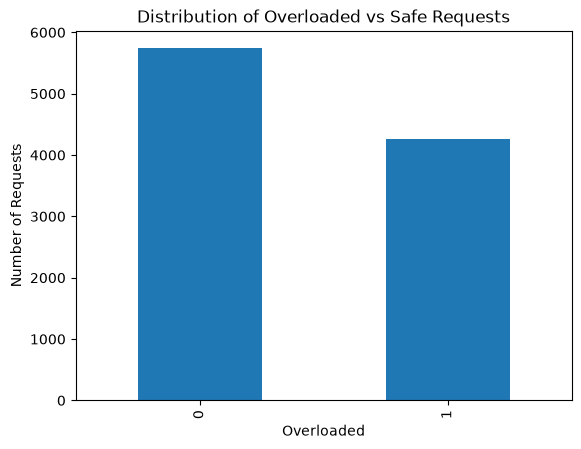

In [24]:
df["Overloaded"].value_counts().plot(kind="bar")

plt.xlabel("Overloaded")
plt.ylabel("Number of Requests")
plt.title("Distribution of Overloaded vs Safe Requests")
plt.show()

In [25]:
df["Queue Length"] = np.random.randint(
    0,
    11,
    size=len(df)
)

In [26]:
df[
    [
        "Task Size (FLOPs)",
        "Deadline (ms)",
        "Data Size (MB)",
        "Latency (ms)",
        "Bandwidth (Mbps)",
        "Server Capacity (FLOPs/sec)",
        "Current CPU Utilization",
        "Queue Length",
        "Overloaded"
    ]
].head(10)

,Task Size (FLOPs),Deadline (ms),Data Size (MB),Latency (ms),Bandwidth (Mbps),Server Capacity (FLOPs/sec),Current CPU Utilization,Queue Length,Overloaded
0,9.681264e+08,958.015964,2.809856,73.054498,120.901113,1.499632e+09,0.461549,5,1
1,3.752580e+08,1147.524027,1.579691,54.089148,81.959794,1.960571e+09,0.433038,1,0
2,8.554945e+08,963.641492,3.205459,96.089489,108.881281,1.785595e+09,0.323308,3,0
3,9.892968e+08,1012.087297,3.274983,86.687099,123.074155,1.678927e+09,0.625087,6,1
4,7.469933e+08,833.089693,2.271693,72.994474,137.999889,1.324815e+09,0.533637,10,1
5,1.030766e+09,1091.614208,3.157788,95.050924,119.208769,1.324796e+09,0.805991,5,1
6,4.569438e+08,1165.890822,1.914334,64.742536,96.937593,1.246467e+09,0.222477,8,0
7,5.612669e+08,1134.020810,1.332001,57.141264,109.827744,1.892941e+09,0.650708,10,0
8,5.524440e+08,1019.629783,1.457559,48.924879,104.230705,1.680892e+09,0.734064,6,1
9,2.661523e+08,965.837927,0.938492,49.918251,75.061106,1.766458e+09,0.731641,0,0


In [27]:
features = [
    "Task Size (FLOPs)",
    "Deadline (ms)",
    "Data Size (MB)",
    "Latency (ms)",
    "Bandwidth (Mbps)",
    "Server Capacity (FLOPs/sec)",
    "Current CPU Utilization",
    "Queue Length"
]

X = df[features]
y = df["Overloaded"]

In [28]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.value_counts())

X shape: (10000, 8)
y shape: (10000,)

Features:
Index(['Task Size (FLOPs)', 'Deadline (ms)', 'Data Size (MB)', 'Latency (ms)',
       'Bandwidth (Mbps)', 'Server Capacity (FLOPs/sec)',
       'Current CPU Utilization', 'Queue Length'],
      dtype='str')

Target:
Overloaded
0    5739
1    4261
Name: count, dtype: int64


In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [30]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTesting target:")
print(y_test.value_counts())

Training data: (8000, 8)
Testing data: (2000, 8)

Training target:
Overloaded
0    4591
1    3409
Name: count, dtype: int64

Testing target:
Overloaded
0    1148
1     852
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (8000, 8)
X_test : (2000, 8)
y_train: (8000,)
y_test : (2000,)


In [32]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [33]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[1 1 0 1 1 1 1 0 0 0 0 1 0 0 0 1 1 1 0 1]


In [34]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7575

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.83      0.80      1148
           1       0.74      0.66      0.70       852

    accuracy                           0.76      2000
   macro avg       0.75      0.75      0.75      2000
weighted avg       0.76      0.76      0.76      2000



In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9705

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1148
           1       0.97      0.96      0.97       852

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



In [36]:
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

Logistic Regression Accuracy: 0.7575
Random Forest Accuracy: 0.9705


In [37]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                       Feature  Importance
6      Current CPU Utilization    0.494721
0            Task Size (FLOPs)    0.138058
2               Data Size (MB)    0.108643
4             Bandwidth (Mbps)    0.067015
5  Server Capacity (FLOPs/sec)    0.063762
3                 Latency (ms)    0.060031
1                Deadline (ms)    0.055502
7                 Queue Length    0.012268


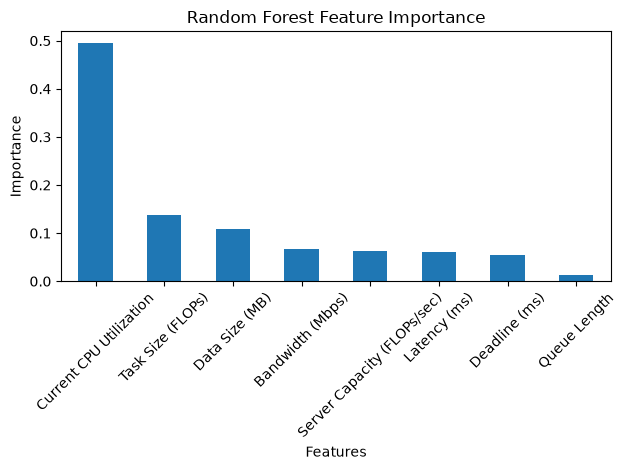

In [38]:
# ==========================================
# FEATURE IMPORTANCE GRAPH
# ==========================================

feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [39]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                       Feature  Importance
6      Current CPU Utilization    0.494721
0            Task Size (FLOPs)    0.138058
2               Data Size (MB)    0.108643
4             Bandwidth (Mbps)    0.067015
5  Server Capacity (FLOPs/sec)    0.063762
3                 Latency (ms)    0.060031
1                Deadline (ms)    0.055502
7                 Queue Length    0.012268


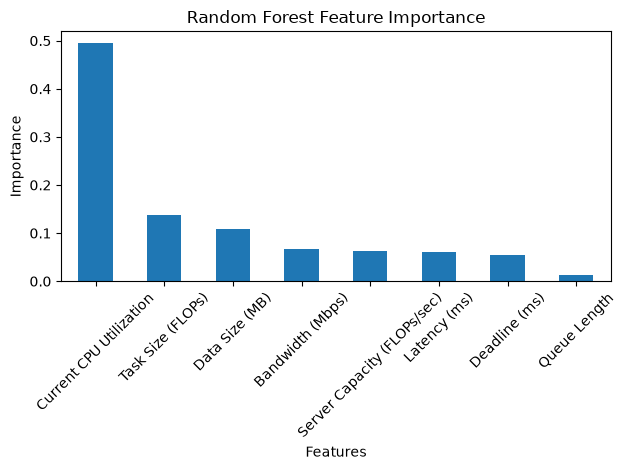

In [40]:
# ==========================================
# FEATURE IMPORTANCE GRAPH
# ==========================================

import matplotlib.pyplot as plt

feature_importance.plot(
    x="Feature",
    y="Importance",
    kind="bar",
    legend=False
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
# ==========================================
# TEST BOTH MODELS ON A NEW REQUEST
# ==========================================

# Example new request
new_request = {
    "Task Size (FLOPs)": 600000000,
    "Deadline (ms)": 1000,
    "Data Size (MB)": 2,
    "Latency (ms)": 50,
    "Bandwidth (Mbps)": 100
}

# Example server state
server = {
    "Server Capacity (FLOPs/sec)": 1500000000,
    "Current CPU Utilization": 0.50,
    "Queue Length": 3
}

# ==========================================
# CREATE INPUT FOR BOTH MODELS
# ==========================================

new_input = pd.DataFrame([{
    "Task Size (FLOPs)": new_request["Task Size (FLOPs)"],
    "Deadline (ms)": new_request["Deadline (ms)"],
    "Data Size (MB)": new_request["Data Size (MB)"],
    "Latency (ms)": new_request["Latency (ms)"],
    "Bandwidth (Mbps)": new_request["Bandwidth (Mbps)"],
    "Server Capacity (FLOPs/sec)": server["Server Capacity (FLOPs/sec)"],
    "Current CPU Utilization": server["Current CPU Utilization"],
    "Queue Length": server["Queue Length"]
}])

# ==========================================
# LOGISTIC REGRESSION PREDICTION
# ==========================================

lr_prediction = model.predict(new_input)[0]
lr_probability = model.predict_proba(new_input)[0][1]

if lr_prediction == 1:
    lr_result = "OVERLOADED"
else:
    lr_result = "SAFE"


# ==========================================
# RANDOM FOREST PREDICTION
# ==========================================

rf_prediction = rf_model.predict(new_input)[0]
rf_probability = rf_model.predict_proba(new_input)[0][1]

if rf_prediction == 1:
    rf_result = "OVERLOADED"
else:
    rf_result = "SAFE"


# ==========================================
# DISPLAY RESULTS SIDE BY SIDE
# ==========================================

print("=" * 60)
print("             MODEL PREDICTION COMPARISON")
print("=" * 60)

print(f"{'Model':<25} {'Prediction':<20} {'Overload Probability'}")
print("-" * 60)

print(f"{'Logistic Regression':<25} {lr_result:<20} {lr_probability:.4f}")
print(f"{'Random Forest':<25} {rf_result:<20} {rf_probability:.4f}")

print("=" * 60)

             MODEL PREDICTION COMPARISON
Model                     Prediction           Overload Probability
------------------------------------------------------------
Logistic Regression       SAFE                 0.4680
Random Forest             SAFE                 0.1600


In [42]:
# ==========================================
# TEST ONE REQUEST ON MULTIPLE SERVERS
# ==========================================

# New request
new_request = {
    "Task Size (FLOPs)": 600000000,
    "Deadline (ms)": 1000,
    "Data Size (MB)": 2,
    "Latency (ms)": 50,
    "Bandwidth (Mbps)": 100
}

# Create 10 example edge servers
servers = [
    {"Server": "Edge-1", "Capacity": 1500000000, "CPU": 0.30, "Queue": 2},
    {"Server": "Edge-2", "Capacity": 1500000000, "CPU": 0.70, "Queue": 5},
    {"Server": "Edge-3", "Capacity": 2000000000, "CPU": 0.40, "Queue": 1},
    {"Server": "Edge-4", "Capacity": 1000000000, "CPU": 0.80, "Queue": 6},
    {"Server": "Edge-5", "Capacity": 1800000000, "CPU": 0.50, "Queue": 3},
    {"Server": "Edge-6", "Capacity": 1500000000, "CPU": 0.90, "Queue": 8},
    {"Server": "Edge-7", "Capacity": 2500000000, "CPU": 0.35, "Queue": 2},
    {"Server": "Edge-8", "Capacity": 1200000000, "CPU": 0.60, "Queue": 4},
    {"Server": "Edge-9", "Capacity": 2000000000, "CPU": 0.75, "Queue": 5},
    {"Server": "Edge-10", "Capacity": 1500000000, "CPU": 0.45, "Queue": 1}
]

# Store results
results = []

# ==========================================
# RUN BOTH MODELS FOR EVERY SERVER
# ==========================================

for s in servers:

    new_input = pd.DataFrame([{
        "Task Size (FLOPs)": new_request["Task Size (FLOPs)"],
        "Deadline (ms)": new_request["Deadline (ms)"],
        "Data Size (MB)": new_request["Data Size (MB)"],
        "Latency (ms)": new_request["Latency (ms)"],
        "Bandwidth (Mbps)": new_request["Bandwidth (Mbps)"],
        "Server Capacity (FLOPs/sec)": s["Capacity"],
        "Current CPU Utilization": s["CPU"],
        "Queue Length": s["Queue"]
    }])

    # Logistic Regression
    lr_prediction = model.predict(new_input)[0]
    lr_probability = model.predict_proba(new_input)[0][1]

    # Random Forest
    rf_prediction = rf_model.predict(new_input)[0]
    rf_probability = rf_model.predict_proba(new_input)[0][1]

    results.append({
        "Server": s["Server"],
        "CPU Utilization": s["CPU"],
        "Queue": s["Queue"],
        "LR Prediction": "OVERLOADED" if lr_prediction == 1 else "SAFE",
        "LR Probability": lr_probability,
        "RF Prediction": "OVERLOADED" if rf_prediction == 1 else "SAFE",
        "RF Probability": rf_probability
    })


# ==========================================
# DISPLAY RESULTS
# ==========================================

results_df = pd.DataFrame(results)

print("=" * 100)
print("                 SERVER PREDICTION COMPARISON")
print("=" * 100)

print(results_df.to_string(index=False))

print("=" * 100)

                 SERVER PREDICTION COMPARISON
 Server  CPU Utilization  Queue LR Prediction  LR Probability RF Prediction  RF Probability
 Edge-1             0.30      2          SAFE        0.467988          SAFE            0.06
 Edge-2             0.70      5          SAFE        0.467988    OVERLOADED            0.91
 Edge-3             0.40      1          SAFE        0.230659          SAFE            0.06
 Edge-4             0.80      6    OVERLOADED        0.720742    OVERLOADED            0.96
 Edge-5             0.50      3          SAFE        0.315604          SAFE            0.08
 Edge-6             0.90      8          SAFE        0.467988    OVERLOADED            0.95
 Edge-7             0.35      2          SAFE        0.092712          SAFE            0.06
 Edge-8             0.60      4    OVERLOADED        0.626586          SAFE            0.48
 Edge-9             0.75      5          SAFE        0.230659    OVERLOADED            0.87
Edge-10             0.45      1   

In [43]:
# ==========================================
# GRADIENT BOOSTING CLASSIFIER
# ==========================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

gb_accuracy = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:", gb_accuracy)

print("\nGradient Boosting Classification Report:")
print(classification_report(y_test, y_pred_gb))

Gradient Boosting Accuracy: 0.98

Gradient Boosting Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1148
           1       0.98      0.98      0.98       852

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



In [44]:
# ==========================================
# COMPARE ALL 3 MODELS
# ==========================================

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, model.predict(X_test)),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb)
    ],
    
    "Precision": [
        precision_score(y_test, model.predict(X_test)),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb)
    ],
    
    "Recall": [
        recall_score(y_test, model.predict(X_test)),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb)
    ],
    
    "F1-Score": [
        f1_score(y_test, model.predict(X_test)),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7575,0.739869,0.664319,0.700062
1,Random Forest,0.9705,0.968123,0.962441,0.965274
2,Gradient Boosting,0.9800,0.977647,0.975352,0.976498


In [46]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 3.0 MB/s eta 0:00:17
   - -------------------------------------- 1.8/48.9 MB 4.2 MB/s eta 0:00:12
   -- ------------------------------------- 3.4/48.9 MB 5.4 MB/s eta 0:00:09
   ---- ----------------------------------- 6.0/48.9 MB 6.9 MB/s eta 0:00:07
   ------- -------------------------------- 9.2/48.9 MB 8.5 MB/s eta 0:00:05
   ---------- ----------------------------- 13.4/48.9 MB 10.5 MB/s eta 0:00:04
   --------------- ------------------------ 18.6/48.9 MB 12.4 MB/s eta 0:00:03
   -------------------- ------------------- 24.6/48.9 MB 14.4 MB/s eta 0:00:02
   -------------------------- ------------- 32.5/48.9 MB 16.7 MB/s eta 0:00:01
   -------------------------------- ------- 39.8/48.9 MB 18.5 MB/s eta 0:00:01
   ---------------------------------------  48.0/48.9 MB 20.2 MB/s eta 0:00:01
 

In [47]:
# ==========================================
# XGBOOST CLASSIFIER
# ==========================================

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9795

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1148
           1       0.98      0.98      0.98       852

    accuracy                           0.98      2000
   macro avg       0.98      0.98      0.98      2000
weighted avg       0.98      0.98      0.98      2000



In [48]:
# ==========================================
# DECISION TREE CLASSIFIER
# ==========================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.923

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.96      0.93      1148
           1       0.94      0.87      0.91       852

    accuracy                           0.92      2000
   macro avg       0.93      0.92      0.92      2000
weighted avg       0.92      0.92      0.92      2000



In [49]:
# ==========================================
# FINAL 5-MODEL COMPARISON
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, model.predict(X_test)),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, model.predict(X_test)),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, model.predict(X_test)),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1-Score": [
        f1_score(y_test, model.predict(X_test)),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_xgb)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.7575,0.739869,0.664319,0.700062
1,Decision Tree,0.9230,0.942893,0.872066,0.906098
2,Random Forest,0.9705,0.968123,0.962441,0.965274
3,Gradient Boosting,0.9800,0.977647,0.975352,0.976498
4,XGBoost,0.9795,0.975381,0.976526,0.975953



Logistic Regression
[[949 199]
 [286 566]]


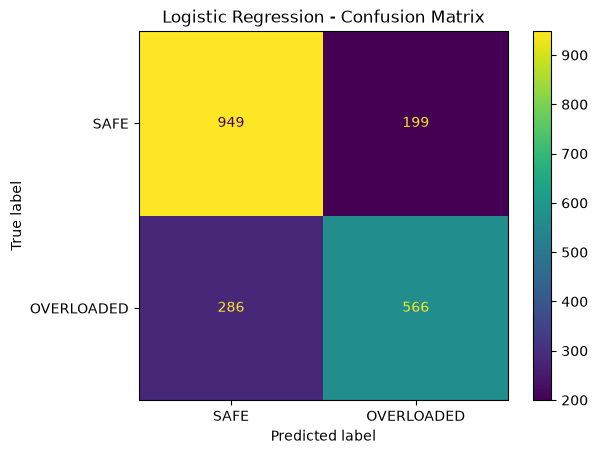


Decision Tree
[[1103   45]
 [ 109  743]]


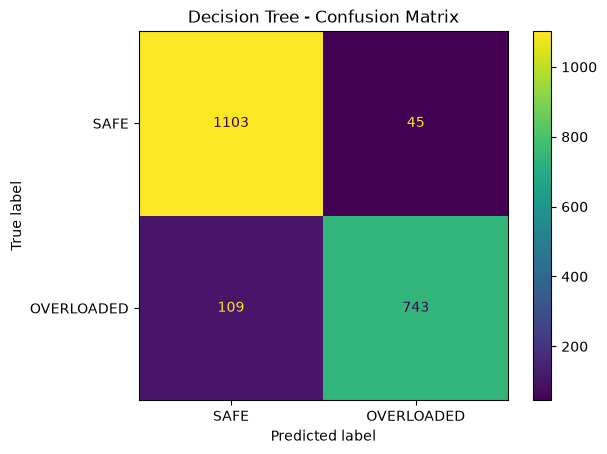


Random Forest
[[1121   27]
 [  32  820]]


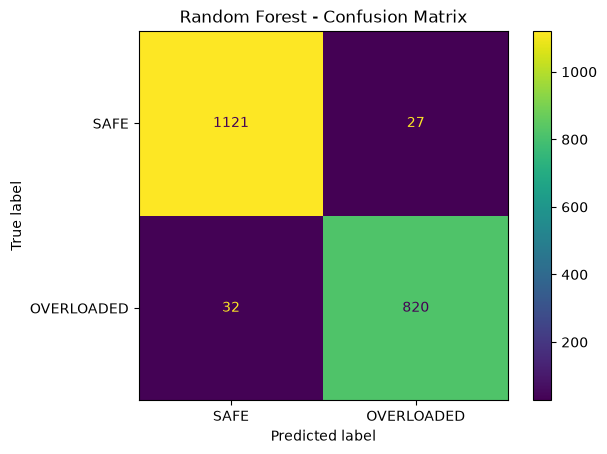


Gradient Boosting
[[1129   19]
 [  21  831]]


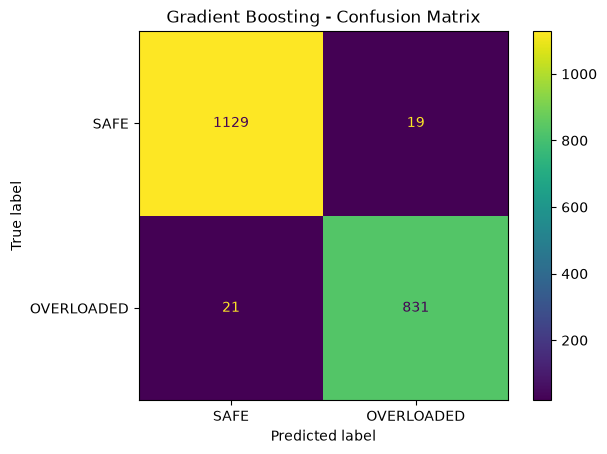


XGBoost
[[1127   21]
 [  20  832]]


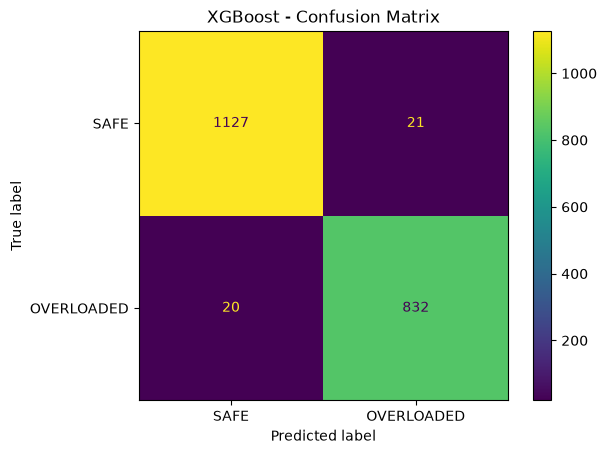

In [50]:
# ==========================================
# CONFUSION MATRICES FOR ALL 5 MODELS
# ==========================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models_predictions = {
    "Logistic Regression": model.predict(X_test),
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb
}

for name, predictions in models_predictions.items():
    cm = confusion_matrix(y_test, predictions)

    print(f"\n{name}")
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["SAFE", "OVERLOADED"]
    )

    disp.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.show()

In [51]:
# ==========================================
# MODEL REGISTRY
# ==========================================

models = {
    "Logistic Regression": model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

print("Available Models:")
for name in models:
    print("-", name)

Available Models:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting
- XGBoost


In [52]:
# ==========================================
# COMMON PREDICTION FUNCTION
# ==========================================

def predict_with_model(model_name, input_data):

    selected_model = models[model_name]

    prediction = selected_model.predict(input_data)[0]

    if prediction == 1:
        return "OVERLOADED"
    else:
        return "SAFE"

In [53]:
# ==========================================
# CREATE 10 EDGE SERVERS
# ==========================================

import numpy as np
import pandas as pd

np.random.seed(100)

servers = pd.DataFrame({
    "Server ID": [f"Edge-{i+1}" for i in range(10)],
    
    "Server Capacity (FLOPs/sec)": np.random.uniform(
        1.2e9,
        2.0e9,
        10
    ),
    
    "Current CPU Utilization": np.random.uniform(
        0.2,
        0.9,
        10
    ),
    
    "Queue Length": np.random.randint(
        0,
        11,
        10
    )
})

# Calculate current load
servers["Current Load (FLOPs/sec)"] = (
    servers["Server Capacity (FLOPs/sec)"] *
    servers["Current CPU Utilization"]
)

servers

,Server ID,Server Capacity (FLOPs/sec),Current CPU Utilization,Queue Length,Current Load (FLOPs/sec)
0,Edge-1,1.634724e+09,0.823925,3,1.346891e+09
1,Edge-2,1.422696e+09,0.346441,7,4.928807e+08
2,Edge-3,1.539614e+09,0.329730,1,5.076566e+08
3,Edge-4,1.875821e+09,0.275864,1,5.174711e+08
4,Edge-5,1.203775e+09,0.353788,7,4.258815e+08
5,Edge-6,1.297255e+09,0.885037,7,1.148118e+09
6,Edge-7,1.736599e+09,0.768178,0,1.334018e+09
7,Edge-8,1.860682e+09,0.320359,2,5.960857e+08
8,Edge-9,1.309365e+09,0.771357,9,1.009988e+09
9,Edge-10,1.660075e+09,0.391852,9,6.505030e+08


In [54]:
# ==========================================
# CREATE ONE INCOMING REQUEST
# ==========================================

request = {
    "Task Size (FLOPs)": 5e9,
    "Deadline (ms)": 500,
    "Data Size (MB)": 20,
    "Latency (ms)": 20,
    "Bandwidth (Mbps)": 100
}

request

{'Task Size (FLOPs)': 5000000000.0,
 'Deadline (ms)': 500,
 'Data Size (MB)': 20,
 'Latency (ms)': 20,
 'Bandwidth (Mbps)': 100}

In [55]:
# ==========================================
# TEST REQUEST AGAINST ALL EDGE SERVERS
# ==========================================

model_name = "XGBoost"

results = []

for _, server in servers.iterrows():

    input_data = pd.DataFrame([{
        "Task Size (FLOPs)": request["Task Size (FLOPs)"],
        "Deadline (ms)": request["Deadline (ms)"],
        "Data Size (MB)": request["Data Size (MB)"],
        "Latency (ms)": request["Latency (ms)"],
        "Bandwidth (Mbps)": request["Bandwidth (Mbps)"],
        "Server Capacity (FLOPs/sec)": server["Server Capacity (FLOPs/sec)"],
        "Current CPU Utilization": server["Current CPU Utilization"],
        "Queue Length": server["Queue Length"]
    }])

    prediction = predict_with_model(
        model_name,
        input_data
    )

    results.append({
        "Server": server["Server ID"],
        "Prediction": prediction
    })

results_df = pd.DataFrame(results)

results_df

,Server,Prediction
0,Edge-1,OVERLOADED
1,Edge-2,OVERLOADED
2,Edge-3,OVERLOADED
3,Edge-4,SAFE
4,Edge-5,OVERLOADED
5,Edge-6,OVERLOADED
6,Edge-7,OVERLOADED
7,Edge-8,SAFE
8,Edge-9,OVERLOADED
9,Edge-10,OVERLOADED
